# Project 2

## Research Question: What factors are associated with students' final grades?

## Introduction

My research question is: **What factors are associated with students' final grades?** The purpose of this project is to investigate whether sex, school absences, and study time are associated with academic performance. To explore this question, I selected the *Student Performance* dataset from the UCI Machine Learning Repository. The dataset contains information about students from two Portuguese secondary schools, including their academic results, absences, study habits, and family backgrounds. I chose this dataset because it provides information that can be used to investigate factors associated with students' academic performance through statistical analysis.

For this project, I will focus on four variables: `sex`, `absences`, `studytime`, and `G3`. The `sex` variable identifies students as female or male. The `absences` variable represents the number of school absences recorded for each student during the school year, ranging from 0 to 75 in the mathematics dataset. The `studytime` variable represents weekly study time in four categories: less than 2 hours, 2–5 hours, 5–10 hours, and more than 10 hours. Finally, `G3` represents the student's final grade on a scale from 0 to 20.

I will investigate three relationships: whether final grades differ between female and male students, whether the number of absences is associated with final grades, and whether study time is associated with final grades. I will use hypothesis tests, confidence intervals, and visualizations to explore these relationships. 

-----------

## Data Analysis & Statistical Inference

#### Analysis

For this project, I will analyze three relationships between students' characteristics or habits and their final grades.

**1. Sex and Final Grades — Independent-Samples t-Test**

I will compare the average final grades of female and male students using an independent-samples t-test.

- Group 1: Female students.
- Group 2: Male students.

My hypotheses are:

- H₀: Female and male students have equal population mean final grades.
- H₁: Female and male students have different population mean final grades.

**2. Absences and Final Grades — Independent-Samples t-Test**

I will compare the average final grades of students with fewer absences to those of students with more absences.

- Group 1: Students with 1–5 absences.
- Group 2: Students with 10 or more absences.

My hypotheses are:

- H₀: The two groups have equal population mean final grades.
- H₁: Students with 1–5 absences have a higher population mean final grade than students with 10 or more absences.

**3. Study Time and Final Grades — One-Way ANOVA**

I will examine whether average final grades differ across the four weekly study-time categories.

- Group 1: Students studying less than 2 hours per week.
- Group 2: Students studying 2–5 hours per week.
- Group 3: Students studying 5–10 hours per week.
- Group 4: Students studying more than 10 hours per week.

My hypotheses are:

- H₀: All four groups have equal population mean final grades.
- H₁: At least one group's population mean final grade is different.

I will use appropriate statistical tests and create visualizations for each analysis. Where appropriate, I will also calculate 95% confidence intervals to estimate plausible values for differences in population mean final grades.

#### Result

First, the independent-samples t-test comparing female and male students found a statistically significant difference in average final grades. Male students had an average grade of 10.91, compared with 9.97 for female students, a difference of 0.94 points. The p-value was 0.0399, which is below 0.05. The 95% confidence interval for the difference in means (Female − Male) was (-1.85, -0.05). Therefore, I rejected the null hypothesis. These results suggest that male students had higher average final grades than female students in these two schools.

Second, the independent-samples t-test comparing students with 1–5 absences and students with 10 or more absences found a statistically significant difference in average final grades. Students with 1–5 absences had a higher average grade (11.65) than students with 10 or more absences (10.37), a difference of 1.28 points. The t-statistic was 2.9073, and the p-value was 0.0040. Since the p-value was below 0.05, I rejected the null hypothesis. These results suggest that students with fewer absences had higher average final grades than students with more absences in these two schools.

Finally, I used a one-way ANOVA test to compare average final grades across the four study-time groups. The average grades were 10.05 for Group 1, 10.17 for Group 2, 11.40 for Group 3, and 11.26 for Group 4. The test produced an F-statistic of 1.7278 and a p-value of 0.1607. Since the p-value was greater than 0.05, I failed to reject the null hypothesis. Therefore, the analysis did not find sufficient statistical evidence of a difference in average final grades among the four study-time groups.

-----------

## Conclusion and Future Research

The results of this project showed statistically significant differences in average final grades between male and female students and between students with 1–5 absences and those with 10 or more absences. Male students had higher average grades than female students, and students with fewer absences had higher average grades than students with more absences. However, the ANOVA test did not find sufficient statistical evidence of differences in average grades across the four study-time categories.

**These findings suggest that students' sex and school attendance may be associated with academic performance, while studytime does not have a significant effect. However, these results do not prove that sex or absences are the only causes of differences in final grades. Other factors, such as previous grades, family circumstances, and study habits, may also be related to academic performance.**

For future research, I could examine other variables, such as grades and family background, to better understand which factors are associated with students' academic performance, especially focusing on the family backgroung information.

-----------

## Resources

- UCI Machine Learning Repository. (2008). *Student Performance*. [https://doi.org/10.24432/C5TG7T](https://doi.org/10.24432/C5TG7T)
- SciPy Developers. (n.d.). *scipy.stats.ttest_ind*. SciPy documentation. [https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)


## Loading packages

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
from scipy import stats

## Uploading data

In [170]:
df = pd.read_csv('student-mat.csv', sep = ';')

# Variables I will uses
df[['sex', 'studytime', 'absences', 'G3']]

,sex,studytime,absences,G3
0,F,2,6,6
1,F,2,4,6
2,F,2,10,10
3,F,3,2,15
4,F,2,4,10
...,...,...,...,...
390,M,2,11,9
391,M,1,3,16
392,M,1,3,7
393,M,1,0,10


In [171]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [172]:
# Display the differents absences numbers

df['absences'].unique()

array([ 6,  4, 10,  2,  0, 16, 14,  7,  8, 25, 12, 54, 18, 26, 20, 56, 24,
       28,  5, 13, 15, 22,  3, 21,  1, 75, 30, 19,  9, 11, 38, 40, 23, 17])

In [173]:
# Display the differents study hour categories

df['studytime'].unique()

array([2, 3, 1, 4])

In [174]:
# Check if there is not missing values

df.isna().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

## Hypothesis Testing: Difference in mean -- Independent sample test (Males vs Females)
### Comparing the average final grades of female and male students:
#### H₀: Female and male students have equal population mean final grades.
#### H₁: Female and male students have different population mean final grades.

In [175]:
# Separate final grades into two sex groups (female and male) & comparing the them
Female_students = df[df['sex'] == 'F']['G3']
Male_students = df[df['sex'] == 'M']['G3']

t_stat, t_pval = st.ttest_ind(Female_students, Male_students)

print("Independent T-Test")
print("------------------")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {t_pval:.4f}")
if t_pval < 0.05:
    print("Decision: Reject H0 (Significant difference found)\n")
    if np.mean(Female_students) > np.mean(Male_students):
        print (f"Female students' average final grade ({np.mean(Female_students):.2f}) is higher than Male students' average final grade ({np.mean(Male_students):.2f}) ")
    else:
        print (f"Male students' average final grade ({np.mean(Male_students):.2f}) is higher than Female students' average final grade ({np.mean(Female_students):.2f})")
else:
    print("Decision: Fail to reject H0\n")

Independent T-Test
------------------
T-statistic: -2.0620
P-value: 0.0399
Decision: Reject H0 (Significant difference found)

Male students' average final grade (10.91) is higher than Female students' average final grade (9.97)


## Calculating the Confidence interval for the difference between the two means

In [176]:
Female_students = df[df['sex'] == 'F']['G3']
Male_students = df[df['sex'] == 'M']['G3']

result = stats.ttest_ind(Female_students, Male_students, equal_var=False)

ci = result.confidence_interval(confidence_level=0.95)

print("95% Confidence Interval:", ci)

95% Confidence Interval: ConfidenceInterval(low=np.float64(-1.8507322559611021), high=np.float64(-0.045452441694184165))


## Plot 1: Comparison of female and male students'final grade

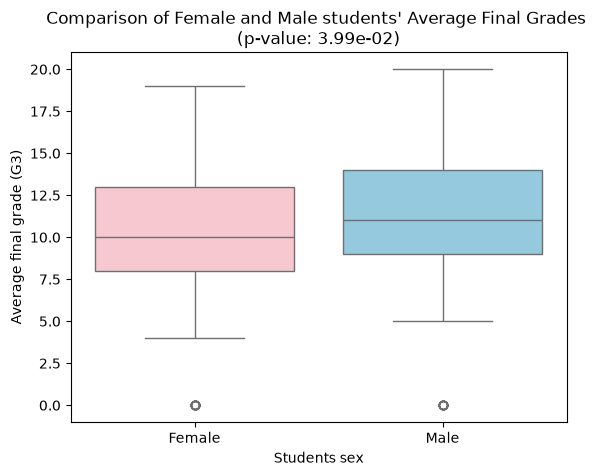

In [177]:
# Visualization of Male and Female students' average final grade
df['sex_group']= np.where(df['sex'] == 'F',
                      "Female",
                      "Male")

sns.boxplot(
    x='sex_group',
    y='G3',
    data=df,
    hue='sex_group',
    palette={'Female': 'pink',
    'Male': 'skyblue'},
    legend=False)

plt.title(f"Comparison of Female and Male students' Average Final Grades \n(p-value: {t_pval:.2e})")
plt.xlabel('Students sex')
plt.ylabel('Average final grade (G3)')
plt.show()

## Hypothesis Testing: Difference in mean -- Independent sample test (Students with 0 absence vs Students with at least 1 absence)
### Comparing Group1 average final grade to Group2 average final grade:
#### H₀: The two groups have equal population mean final grades.
#### H₁: The two groups have different population mean final grades.

In [178]:
# Separating final grades into two abscence groups & comparing the them
group1_finalG = df[(df['absences'] >= 1) & (df['absences'] <= 5)]['G3']
group2_finalG = df[df['absences'] >= 10]['G3']

t_stat, t_pval = st.ttest_ind(group1_finalG,group2_finalG)

print(f"Independent T-Test:")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {t_pval:.4f}")

if t_pval < 0.05:
    print("Decision: Reject H0 (Significant difference found)\n")

    if np.mean(group1_finalG) > np.mean(group2_finalG):
        print(
            f"Students with 1-5 absences (Group 1) tend to have a higher final grade (mean = {np.mean(group1_finalG):.2f}),"
            f"while students with 10 or more absences (Group 2) tend to have a lower final grade (mean = {np.mean(group2_finalG):.2f}).")
    else:
        print(
            f"Students with ten or more absences (Group 2) tend to have a higher final grade (mean = {np.mean(group2_finalG):.2f}),"
            f"while students with 1-5 absences (Group 1) tend to have a lower final grade (mean = {np.mean(group1_finalG):.2f}).")
else:
    print("Decision: Fail to reject H0 (No statistically significant difference found).")

Independent T-Test:
T-statistic: 2.9073
P-value: 0.0040
Decision: Reject H0 (Significant difference found)

Students with 1-5 absences (Group 1) tend to have a higher final grade (mean = 11.65),while students with 10 or more absences (Group 2) tend to have a lower final grade (mean = 10.37).


## Plot 2: Final grade by absence group

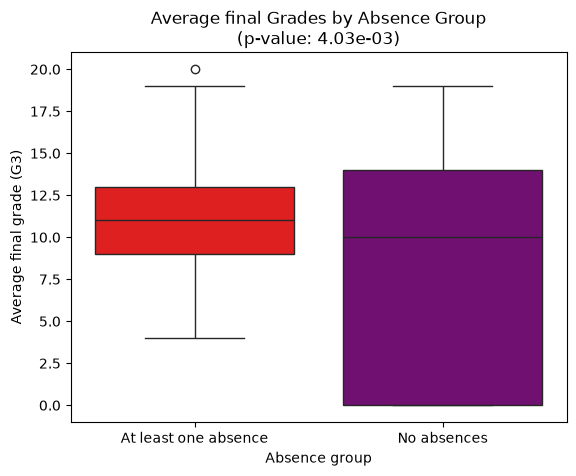

In [179]:
# Visualization of Final grade by absence group
df['absence_group'] = np.where(
    df['absences'] == 0,
    'No absences',
    'At least one absence')

# Create the boxplot
sns.boxplot(
    x='absence_group',
    y='G3',
    data=df,
    hue='absence_group',
    palette={'At least one absence':'red',
            'No absences':'purple'},
    legend=False)

plt.title(f'Average final Grades by Absence Group\n(p-value: {t_pval:.2e})')
plt.xlabel('Absence group')
plt.ylabel('Average final grade (G3)')
plt.show()

## Hypothesis Testing: ANOVA test (Study Time and Final Grades)
### Comparing the study time variable to the final grade one
#### H₀: All four groups have equal population mean final grades.
H₁: At least one group's population mean final grade is different.

In [180]:
# Separating final grades into four study-time groups & comparing the them
Group1 = df[df["studytime"] == 1]['G3']
Group2 = df[df["studytime"] == 2]['G3']
Group3 = df[df["studytime"] == 3]['G3']
Group4 = df[df["studytime"] == 4]['G3']

print(f"mean group1:{np.mean(Group1):.2f} ")
print(f"mean group2:{np.mean(Group2):.2f} ")
print(f"mean group3:{np.mean(Group3):.2f} ")
print(f"mean group4:{np.mean(Group4):.2f} ")

# ANOVA test
f_stat, p_value = stats.f_oneway(
    Group1, Group2, Group3, Group4
)

print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Decision: Reject H0 (Significant difference found)")
else:
    print("Decision: Fail to reject H0 (No significant difference found)")

mean group1:10.05 
mean group2:10.17 
mean group3:11.40 
mean group4:11.26 
F-statistic: 1.7278
P-value: 0.1607
Decision: Fail to reject H0 (No significant difference found)


## Plot 3: Final grade by absence group

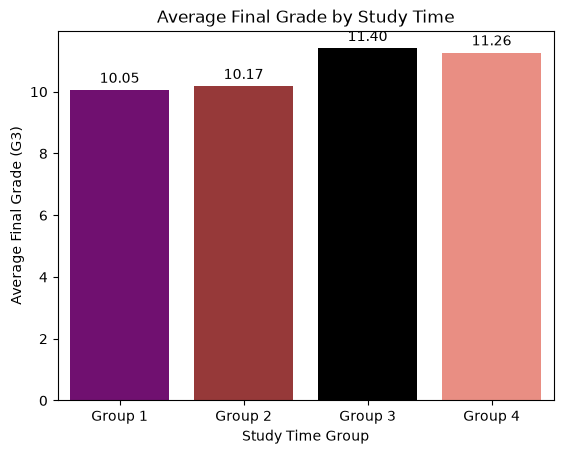

In [181]:
# Visualization of the Average Final Grade by Study Time
# Creating a new column by dividing the studytime column values into 4 groups (because there are 4 types of value)
df["studytime_group"] = df["studytime"].map({
    1: "Group 1",
    2: "Group 2",
    3: "Group 3",
    4: "Group 4" })

sns.barplot(
    x='studytime_group',
    y='G3',
    data=df,
    order=["Group 1", "Group 2", "Group 3", "Group 4"],
    hue='studytime_group',
    palette={
        "Group 1": "purple",
        "Group 2": "brown",
        "Group 3": "black",
        "Group 4": "salmon"},
    legend=False,
    errorbar=None) # Remove the black line

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Group")
plt.ylabel("Average Final Grade (G3)")

for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f", padding=3) # Display the mean studytime for each group

plt.show()